# 01. Exploratory Data Analysis (EDA)
**Bài toán:** phát hiện giao dịch gian lận (`isFraud`) trong dữ liệu giao dịch mobile-money mô phỏng.

**Mục đích notebook:** hiểu dữ liệu *trước khi* xây mô hình. Ta trả lời các câu hỏi sau:
1. Dữ liệu có sạch không (thiếu giá trị, trùng lặp)?
2. Nhãn mất cân bằng đến mức nào?
3. Loại giao dịch nào có gian lận?
4. Số tiền và số dư của giao dịch gian lận khác bình thường thế nào?
5. Cột nào vô dụng và nên bỏ?

**Đầu ra:** các hình trong thư mục `figures/` và file `eda_stats.json` (các con số dùng lại trong báo cáo).

> Cách chạy: đặt `demodataset.csv` cùng thư mục, rồi chọn *Run All*.

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%matplotlib inline
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")

stats = {}  # nơi gom các con số quan trọng, cuối notebook sẽ lưu ra eda_stats.json

## 1. Đọc dữ liệu và kiểm tra tổng quan
Mỗi dòng là một giao dịch. Ta xem vài dòng đầu, kích thước, kiểu dữ liệu, giá trị thiếu và dòng trùng.

In [3]:
df = pd.read_csv("Synthetic_Financial_datasets_log.csv")
display(df.head())
print("Kích thước (dòng, cột):", df.shape)
print()
print(df.dtypes)
print()
print("Tổng số giá trị thiếu:", int(df.isnull().sum().sum()))
print("Số dòng trùng lặp   :", int(df.duplicated().sum()))

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


Kích thước (dòng, cột): (6362620, 11)

step                int64
type                  str
amount            float64
nameOrig              str
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest              str
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Tổng số giá trị thiếu: 0
Số dòng trùng lặp   : 0


In [11]:
stats["n_rows"] = int(len(df))
stats["n_cols"] = int(df.shape[1])
stats["n_missing"] = int(df.isnull().sum().sum())
stats["n_duplicates"] = int(df.duplicated().sum())
stats["n_fraud"] = int(df["isFraud"].sum())
stats["fraud_rate"] = float(df["isFraud"].mean())
stats["step_min"] = int(df["step"].min())
stats["step_max"] = int(df["step"].max())
stats["flagged_sum"] = int(df["isFlaggedFraud"].sum())
stats["n_unique_orig"] = int(df["nameOrig"].nunique())
stats["n_unique_dest"] = int(df["nameDest"].nunique())

print("Số null và lặp của dữ liệu: ", stats["n_missing"], stats["n_duplicates"], "-> không có các dòng trùng hoặc thiếu, dữ liệu sạch")

print("nameOrig có", stats["n_unique_orig"], "giá trị khác nhau trên", stats["n_rows"], "dòng -> gần như là ID -> bỏ")
print("nameDest có", stats["n_unique_dest"], "giá trị khác nhau -> ID -> bỏ")
print("step chỉ chạy từ", stats["step_min"], "đến", stats["step_max"], "(743 giờ) -> chỉ đại diện theo biến thời gian không phải biến thời gian thực tế")

Số null và lặp của dữ liệu:  0 0 -> không có các dòng trùng hoặc thiếu, dữ liệu sạch
nameOrig có 6353307 giá trị khác nhau trên 6362620 dòng -> gần như là ID -> bỏ
nameDest có 2722362 giá trị khác nhau -> ID -> bỏ
step chỉ chạy từ 1 đến 743 (743 giờ) -> chỉ đại diện theo biến thời gian không phải biến thời gian thực tế


**Nhận xét:** dữ liệu sạch (không thiếu, không trùng). Ba cột `isFlaggedFraud`, `nameOrig`, `nameDest` không có giá trị cho mô hình.

## 2. Phân phối nhãn (target)
Điều quan trọng nhất cần biết: gian lận **rất hiếm**. Nếu mô hình luôn đoán "không gian lận" thì accuracy vẫn rất cao, nhưng vô dụng.

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Tỷ lệ gian lận: 0.1291%  (khoảng 1 vụ trên 775 giao dịch)
Accuracy nếu luôn đoán 'bình thường': 99.8709%


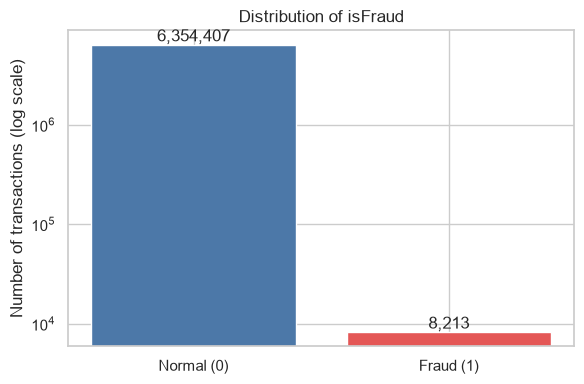

In [12]:
counts = df["isFraud"].value_counts().sort_index()
print(counts)
print(f"\nTỷ lệ gian lận: {stats['fraud_rate']:.4%}  (khoảng 1 vụ trên {round(1/stats['fraud_rate']):,} giao dịch)")
print(f"Accuracy nếu luôn đoán 'bình thường': {1 - stats['fraud_rate']:.4%}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Normal (0)", "Fraud (1)"], counts.values, color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Distribution of isFraud")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("figures/01_label_distribution.png", dpi=150)
plt.show()

**Kết luận:** dữ liệu mất cân bằng nặng, nên sau này **không dùng Accuracy** mà dùng PR-AUC, Recall, Precision, F1.

## 3. Loại giao dịch (`type`) và gian lận

,transactions,fraud_cases,fraud_rate
type,,,
CASH_OUT,2237500,4116,0.001840
PAYMENT,2151495,0,0.000000
CASH_IN,1399284,0,0.000000
TRANSFER,532909,4097,0.007688
DEBIT,41432,0,0.000000


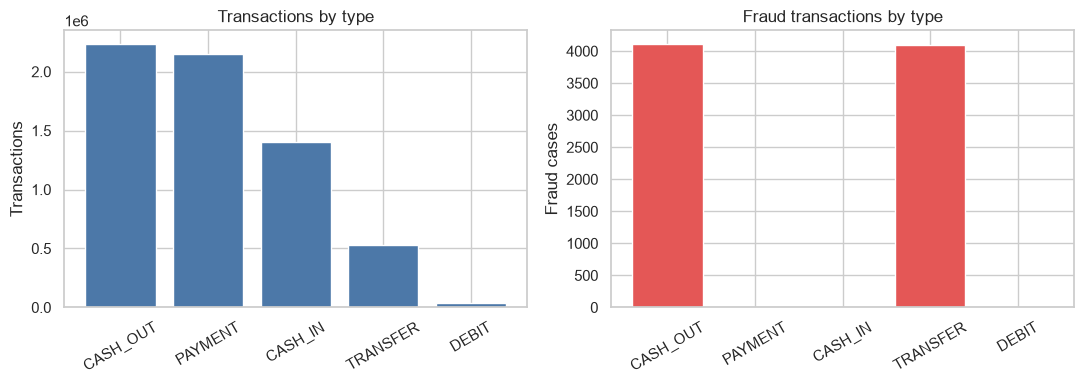

In [13]:
t = df.groupby("type")["isFraud"].agg(["count", "sum", "mean"]).sort_values("count", ascending=False)
t.columns = ["transactions", "fraud_cases", "fraud_rate"]
display(t)
stats["by_type"] = {k: {"count": int(r["transactions"]), "fraud": int(r["fraud_cases"]), "rate": float(r["fraud_rate"])}
                    for k, r in t.iterrows()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(t.index, t["transactions"], color="#4C78A8")
axes[0].set_title("Transactions by type")
axes[0].set_ylabel("Transactions")
axes[1].bar(t.index, t["fraud_cases"], color="#E45756")
axes[1].set_title("Fraud transactions by type")
axes[1].set_ylabel("Fraud cases")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figures/02_type_vs_fraud.png", dpi=150)
plt.show()

**Kết luận:** gian lận chỉ xuất hiện ở **TRANSFER** và **CASH_OUT**. Đặt biệt tỉ lệ cao nổi bật ở TRANSFER khi gian lận ở CASH_OUT và TRANSFER xấp xỉ nhau, nhưng số lượng giao dịch CASH_OUT gấp 4 lần TRANSFER. Kiểu lừa đảo quen thuộc: chuyển tiền ra khỏi tài khoản nạn nhân rồi rút tiền mặt.

## 4. Số tiền giao dịch (`amount`)

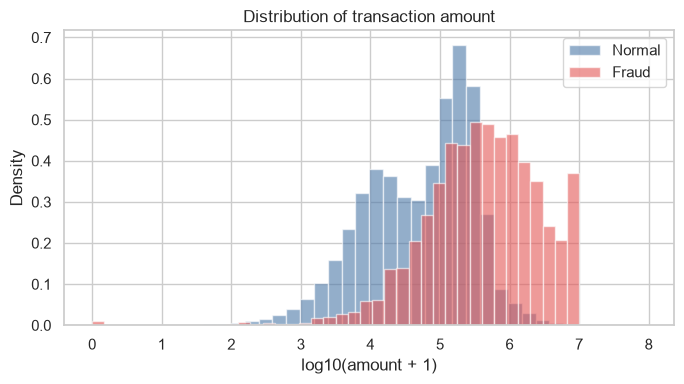

Trung bình  : bình thường 178,197 | gian lận 1,467,967
Trung vị    : bình thường 74,685 | gian lận 441,423


In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, color, name in [(0, "#4C78A8", "Normal"), (1, "#E45756", "Fraud")]:
    sub = df.loc[df["isFraud"] == label, "amount"]
    ax.hist(np.log10(sub + 1), bins=40, alpha=0.6, color=color, label=name, density=True)
ax.set_xlabel("log10(amount + 1)")
ax.set_ylabel("Density")
ax.set_title("Distribution of transaction amount")
ax.legend()
plt.tight_layout()
plt.savefig("figures/03_amount_distribution.png", dpi=150)
plt.show()

f, n = df[df.isFraud == 1], df[df.isFraud == 0]
stats["amount_median_normal"] = float(n["amount"].median())
stats["amount_median_fraud"] = float(f["amount"].median())
stats["amount_mean_normal"] = float(n["amount"].mean())
stats["amount_mean_fraud"] = float(f["amount"].mean())
print(f"Trung bình  : bình thường {stats['amount_mean_normal']:,.0f} | gian lận {stats['amount_mean_fraud']:,.0f}")
print(f"Trung vị    : bình thường {stats['amount_median_normal']:,.0f} | gian lận {stats['amount_median_fraud']:,.0f}")

**Kết luận:** Trung bình và trung vị của các giao dịch gian lận cao hơn hẳn các giao dịch thông thường. Khả năng xảy ra gian lận ở các giao dịch nhỏ là thấp hơn. Khi giao dịch trên 10e5, các giao dịch gian lận xảy ra khá đều đặn. Giao dịch mức 10e7 có tỷ lệ gian lận cao.

## 5. Hành vi của số dư (tín hiệu mạnh nhất)
Một giao dịch bình thường thì số dư người gửi giảm đúng bằng số tiền chuyển. Ta tạo hai đại lượng kiểm tra "số dư có khớp không":
- `errorBalanceOrig = newbalanceOrig + amount - oldbalanceOrg` (bằng 0 nếu khớp)
- `errorBalanceDest = oldbalanceDest + amount - newbalanceDest`

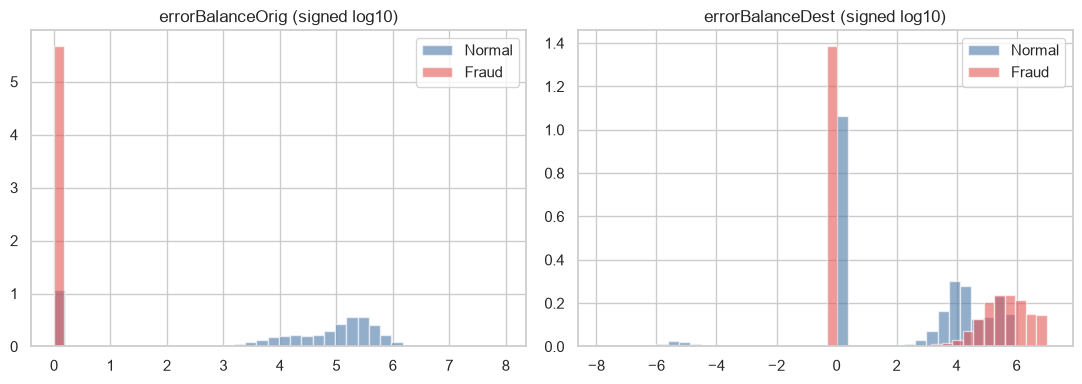

errorBalanceOrig = 0: 8168/8213 vụ gian lận (99.5%) so với 20.0% giao dịch bình thường


In [16]:
df["errorBalanceOrig"] = df["newbalanceOrig"] + df["amount"] - df["oldbalanceOrg"]
df["errorBalanceDest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, col in zip(axes, ["errorBalanceOrig", "errorBalanceDest"]):
    for label, color, name in [(0, "#4C78A8", "Normal"), (1, "#E45756", "Fraud")]:
        sub = df.loc[df["isFraud"] == label, col]
        a.hist(np.sign(sub) * np.log10(np.abs(sub) + 1), bins=40, alpha=0.6, color=color, label=name, density=True)
    a.set_title(col + " (signed log10)")
    a.legend()
plt.tight_layout()
plt.savefig("figures/04_balance_error.png", dpi=150)
plt.show()

f, n = df[df.isFraud == 1], df[df.isFraud == 0]
stats["fraud_eo_zero"] = int((f["errorBalanceOrig"].abs() < 0.01).sum())
stats["fraud_eo_zero_rate"] = float((f["errorBalanceOrig"].abs() < 0.01).mean())
stats["normal_eo_zero_rate"] = float((n["errorBalanceOrig"].abs() < 0.01).mean())
print(f"errorBalanceOrig = 0: {stats['fraud_eo_zero']}/{len(f)} vụ gian lận ({stats['fraud_eo_zero_rate']:.1%}) "
      f"so với {stats['normal_eo_zero_rate']:.1%} giao dịch bình thường")

Tiếp theo: tài khoản người gửi **bị rút sạch** (số dư sau = 0), và tài khoản nhận **trống** trước và sau. Chỉ xét TRANSFER và CASH_OUT vì đây là hai loại có gian lận.

In [18]:
tc = df[df.type.isin(["TRANSFER", "CASH_OUT"])].copy()
tc["emptied"] = (tc["newbalanceOrig"] == 0) & (tc["oldbalanceOrg"] > 0)
e = tc.groupby("emptied")["isFraud"].agg(["count", "sum", "mean"])
e.columns = ["transactions", "fraud_cases", "fraud_rate"]
display(e)
stats["emptied"] = {str(k): {"count": int(r["transactions"]), "fraud": int(r["fraud_cases"]), "rate": float(r["fraud_rate"])}
                    for k, r in e.iterrows()}

dest_empty = (tc["oldbalanceDest"] == 0) & (tc["newbalanceDest"] == 0)
stats["fraud_dest_empty_rate"] = float(dest_empty[tc.isFraud == 1].mean())
stats["normal_tc_dest_empty_rate"] = float(dest_empty[tc.isFraud == 0].mean())
print(f"Tài khoản nhận trống cả trước và sau: gian lận {stats['fraud_dest_empty_rate']:.1%} "
      f"so với bình thường (TRANSFER/CASH_OUT) {stats['normal_tc_dest_empty_rate']:.1%}")

,transactions,fraud_cases,fraud_rate
emptied,,,
False,1582335,201,0.000127
True,1188074,8012,0.006744


Tài khoản nhận trống cả trước và sau: gian lận 49.6% so với bình thường (TRANSFER/CASH_OUT) 0.1%


**Kết luận:** gian lận gần như luôn *rút sạch* tài khoản gửi và hay chuyển vào tài khoản đích còn trống. Đây là cơ sở để tạo các đặc trưng (feature) mới ở notebook 02: `errorBalanceOrig`, `errorBalanceDest`, `origEmptied`, `destEmpty`.

## 6. Thời gian (`step`) và tương quan

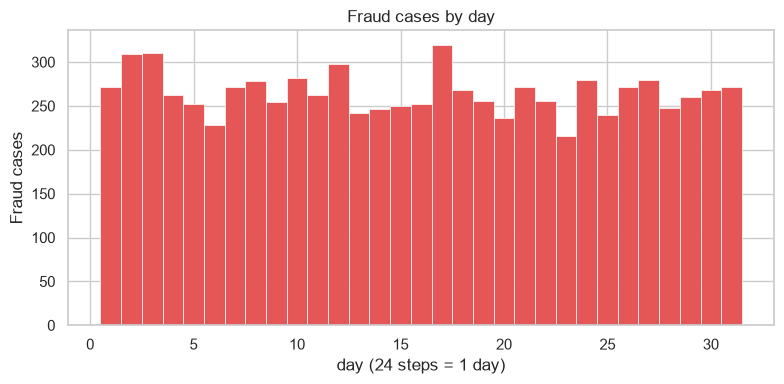

Số step khác nhau: 743 | gian lận mỗi step: min 0 ; max 40


In [34]:
# Số vụ gian lận theo từng step
s = df.groupby("step")["isFraud"].agg(["sum", "count"])
stats["fraud_by_step"] = {int(k): int(v) for k, v in s["sum"].items()}

grp, xlabel = ((df["step"] - 1) // 24 + 1, "day (24 steps = 1 day)") 
g = df.groupby(grp)["isFraud"].agg(["sum", "count"])

fig, ax = plt.subplots(figsize=(8, 4), facecolor="white")
bars = ax.bar(g.index, g["sum"], width=1.0, color="#E45756", edgecolor="white", linewidth=0.5)

ax.set_xlabel(xlabel)
ax.set_ylabel("Fraud cases")
ax.set_title("Fraud cases by " + "day")
plt.tight_layout()
plt.savefig("figures/05_fraud_by_step.png", dpi=150, facecolor="white")
plt.show()
print("Số step khác nhau:", df["step"].nunique(), "| gian lận mỗi step: min", s["sum"].min(),"; max", s["sum"].max())

**Nhận xét:**
- Gian lận rải đều theo `step`, không có xu hướng rõ → bỏ `step`.

## 7. Kiểm tra quan hệ của cờ và gian lận

In [44]:
n_flag = int(df["isFlaggedFraud"].sum())
print("Số lượng cờ được cắm: ",n_flag)

n_fraud = int(df["isFraud"].sum())
fraud_flagged = int(df.loc[df["isFlaggedFraud"] == 1, "isFraud"].sum())
if fraud_flagged == n_flag:
   print("100% giao dịch bị cờ đều là gian lận. Không rõ gắn cờ trước hay sau biết kết quả, bởi nếu gắn cờ sau khi có kết quả thì sẽ bị data leakage. Để an toàn và không bị rò rỉ nhãn, nên bỏ cột này ra khỏi dữ liệu huấn luyện.")

Số lượng cờ được cắm:  16
100% giao dịch bị cờ đều là gian lận. Không rõ gắn cờ trước hay sau biết kết quả, bởi nếu gắn cờ sau khi có kết quả thì sẽ bị data leakage. Để an toàn và không bị rò rỉ nhãn, nên bỏ cột này ra khỏi dữ liệu huấn luyện.


## 8. Ma trận tương quan

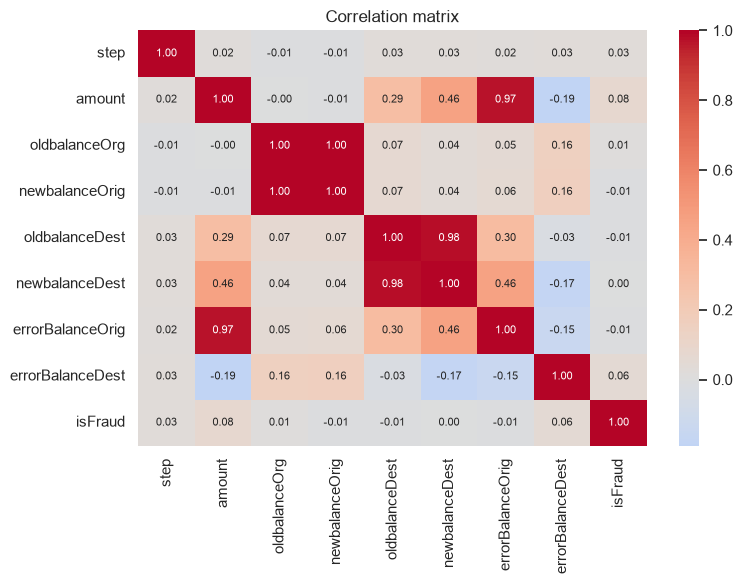

In [46]:
num = df[["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
          "errorBalanceOrig", "errorBalanceDest", "isFraud"]]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("figures/06_correlation.png", dpi=150)
plt.show()
stats["corr_with_fraud"] = {k: float(v) for k, v in num.corr()["isFraud"].drop("isFraud").items()}

**Nhận xét:**

- Tương quan tuyến tính với `isFraud` rất yếu (|r| ≤ 0.04) → tín hiệu nằm ở **sự kết hợp phi tuyến** của nhiều cột, nên mô hình dạng cây (Random Forest, XGBoost) sẽ phù hợp hơn mô hình tuyến tính.
- `oldbalanceOrg` và `newbalanceOrig` gần như trùng nhau (r = 1.00), `oldbalanceDest` và `newbalanceDest` cũng vậy (0.95).

## 9. Lưu số liệu và kết luận EDA

In [32]:
with open("eda_stats.json", "w", encoding="utf-8") as fh:
    json.dump(stats, fh, ensure_ascii=False, indent=2)
print("Đã lưu eda_stats.json")

Đã lưu eda_stats.json


### Kết luận EDA → quyết định cho bước sau
| Phát hiện | Quyết định |
|---|---|
| Fraud chỉ ~0.07% | Không dùng Accuracy; dùng PR-AUC, Recall, Precision, F1; xử lý mất cân bằng |
| Chỉ TRANSFER và CASH_OUT có fraud | Giữ cột `type` (one-hot) |
| Rút sạch tài khoản + số dư không khớp | Tạo 4 đặc trưng mới |
| `nameOrig`, `nameDest`, `step` vô ích, `isFlaggedFraud` có thể data leakage | Bỏ |
| Tương quan tuyến tính yếu | Ưu tiên mô hình dạng cây |
| Không có giá trị thiếu/trùng | Không cần làm sạch thêm |

Tiếp tục với `02_Modelling_and_Evaluation.ipynb`.